<a href="https://colab.research.google.com/github/Higor-V/Higor-V-NaiveJus-ML-Bruno-Higor-Yuri/blob/main/NatJus_NaiveBayes_MCP_3_0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip -q install scikit-learn pypdf python-docx joblib "fastmcp>=2.10"

import io
import re
import unicodedata
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import (train_test_split, GridSearchCV,
                                     RepeatedStratifiedKFold, cross_val_predict)
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

SEMENTE = 42
CATEGORIAS = ["medicamento", "cirurgia", "exame", "tratamento"]
print("Bibliotecas prontas.")

Bibliotecas prontas.


## 1. Base de dados (fictícia)
Os 80 exemplos originais e mais 40 novos, com vocabulário mais técnico (nomes de procedimentos, fármacos e exames) e alguns casos difíceis, como *quimioterápico oral* (medicamento) × *sessões de quimioterapia* (tratamento).

In [2]:
dados = [
    {"texto": "O requerente solicita o fornecimento do medicamento prescrito pelo médico.", "categoria": "medicamento"},
    {"texto": "Pedido judicial para disponibilização de fármaco de uso contínuo.", "categoria": "medicamento"},
    {"texto": "A parte autora requer medicamento de alto custo não fornecido regularmente.", "categoria": "medicamento"},
    {"texto": "Solicita-se a entrega do remédio indicado na receita médica.", "categoria": "medicamento"},
    {"texto": "O paciente pede o fornecimento de comprimidos para controle da doença.", "categoria": "medicamento"},
    {"texto": "A ação requer acesso a medicamento registrado na Anvisa.", "categoria": "medicamento"},
    {"texto": "A demanda trata da falta de medicamento na farmácia pública.", "categoria": "medicamento"},
    {"texto": "O autor solicita insulina e outros medicamentos para uso diário.", "categoria": "medicamento"},
    {"texto": "Pedido de fornecimento de medicamento oncológico conforme prescrição.", "categoria": "medicamento"},
    {"texto": "A petição pede um fármaco específico para continuidade da terapia.", "categoria": "medicamento"},
    {"texto": "Requer-se que o município disponibilize o remédio receitado.", "categoria": "medicamento"},
    {"texto": "O processo discute a dispensação de medicamento pelo SUS.", "categoria": "medicamento"},
    {"texto": "A família solicita a compra de medicamento que não está disponível.", "categoria": "medicamento"},
    {"texto": "O pedido busca garantir o acesso ao princípio ativo indicado pelo especialista.", "categoria": "medicamento"},
    {"texto": "A parte requer a renovação do fornecimento de medicamento de uso prolongado.", "categoria": "medicamento"},
    {"texto": "Solicita-se medicamento imunobiológico para tratamento de doença crônica.", "categoria": "medicamento"},
    {"texto": "O paciente pede o fornecimento de cápsulas prescritas em relatório clínico.", "categoria": "medicamento"},
    {"texto": "A demanda judicial busca obter o fármaco prescrito e indisponível na rede pública.", "categoria": "medicamento"},
    {"texto": "A petição solicita a dispensação de antibiótico conforme receita.", "categoria": "medicamento"},
    {"texto": "O requerente pede que o Estado forneça os medicamentos descritos na prescrição.", "categoria": "medicamento"},
    {"texto": "O requerente solicita a realização de cirurgia ortopédica.", "categoria": "cirurgia"},
    {"texto": "Pedido judicial para agendamento de procedimento cirúrgico urgente.", "categoria": "cirurgia"},
    {"texto": "A parte autora requer cirurgia para correção de hérnia.", "categoria": "cirurgia"},
    {"texto": "O paciente aguarda intervenção cirúrgica pelo sistema público.", "categoria": "cirurgia"},
    {"texto": "A demanda trata da realização de cirurgia cardíaca.", "categoria": "cirurgia"},
    {"texto": "Solicita-se autorização para procedimento cirúrgico indicado pelo especialista.", "categoria": "cirurgia"},
    {"texto": "O processo pede cirurgia de catarata na rede pública.", "categoria": "cirurgia"},
    {"texto": "O autor busca reduzir a fila para uma operação de coluna.", "categoria": "cirurgia"},
    {"texto": "A petição requer cirurgia bariátrica após avaliação médica.", "categoria": "cirurgia"},
    {"texto": "O paciente precisa de cirurgia para retirada de tumor.", "categoria": "cirurgia"},
    {"texto": "A família pede a realização de transplante conforme indicação clínica.", "categoria": "cirurgia"},
    {"texto": "O pedido é para uma intervenção cirúrgica reparadora.", "categoria": "cirurgia"},
    {"texto": "A ação solicita cirurgia vascular em hospital conveniado.", "categoria": "cirurgia"},
    {"texto": "O requerente pede operação para tratamento de lesão no joelho.", "categoria": "cirurgia"},
    {"texto": "A demanda busca autorização de cirurgia neurológica.", "categoria": "cirurgia"},
    {"texto": "O paciente aguarda procedimento cirúrgico eletivo há vários meses.", "categoria": "cirurgia"},
    {"texto": "Solicita-se cirurgia para correção de catarata bilateral.", "categoria": "cirurgia"},
    {"texto": "A petição pede que o ente público providencie a operação recomendada.", "categoria": "cirurgia"},
    {"texto": "O pedido judicial refere-se a cirurgia de prótese de quadril.", "categoria": "cirurgia"},
    {"texto": "O autor requer internação para realização de procedimento cirúrgico.", "categoria": "cirurgia"},
    {"texto": "O requerente solicita a realização de exame de ressonância magnética.", "categoria": "exame"},
    {"texto": "Pedido para agendamento de tomografia computadorizada.", "categoria": "exame"},
    {"texto": "A parte autora requer exame laboratorial específico.", "categoria": "exame"},
    {"texto": "O paciente aguarda ultrassonografia pela rede pública.", "categoria": "exame"},
    {"texto": "A demanda trata do acesso a exame de colonoscopia.", "categoria": "exame"},
    {"texto": "Solicita-se exame de sangue para investigação diagnóstica.", "categoria": "exame"},
    {"texto": "O processo pede uma mamografia que ainda não foi agendada.", "categoria": "exame"},
    {"texto": "O autor requer ecocardiograma solicitado pelo cardiologista.", "categoria": "exame"},
    {"texto": "A petição busca garantir o exame de biópsia.", "categoria": "exame"},
    {"texto": "O paciente precisa realizar uma endoscopia digestiva.", "categoria": "exame"},
    {"texto": "A família solicita exame de imagem para esclarecer o diagnóstico.", "categoria": "exame"},
    {"texto": "O pedido judicial trata da realização de eletroencefalograma.", "categoria": "exame"},
    {"texto": "O requerente pede teste genético para investigação clínica.", "categoria": "exame"},
    {"texto": "A demanda é sobre exame de densitometria óssea.", "categoria": "exame"},
    {"texto": "O paciente necessita de cintilografia indicada em relatório.", "categoria": "exame"},
    {"texto": "Solicita-se teste diagnóstico que não está disponível no município.", "categoria": "exame"},
    {"texto": "A petição requer exame de angiografia para avaliar os vasos.", "categoria": "exame"},
    {"texto": "O autor pede coleta e análise laboratorial de amostras.", "categoria": "exame"},
    {"texto": "O processo solicita exame de PET-CT para avaliação médica.", "categoria": "exame"},
    {"texto": "A ação busca agendamento de exame oftalmológico especializado.", "categoria": "exame"},
    {"texto": "O requerente solicita sessões de fisioterapia para reabilitação.", "categoria": "tratamento"},
    {"texto": "Pedido judicial para iniciar radioterapia conforme plano terapêutico.", "categoria": "tratamento"},
    {"texto": "A parte autora requer acompanhamento psicológico continuado.", "categoria": "tratamento"},
    {"texto": "O paciente necessita de tratamento fonoaudiológico.", "categoria": "tratamento"},
    {"texto": "A demanda trata de sessões de hemodiálise.", "categoria": "tratamento"},
    {"texto": "Solicita-se terapia ocupacional para recuperar a autonomia funcional.", "categoria": "tratamento"},
    {"texto": "O processo pede tratamento multidisciplinar para reabilitação.", "categoria": "tratamento"},
    {"texto": "O autor requer acesso a quimioterapia em serviço especializado.", "categoria": "tratamento"},
    {"texto": "A família solicita atendimento domiciliar de reabilitação.", "categoria": "tratamento"},
    {"texto": "O paciente aguarda tratamento especializado para sua condição.", "categoria": "tratamento"},
    {"texto": "A petição pede sessões de psicoterapia pela rede pública.", "categoria": "tratamento"},
    {"texto": "O requerente solicita tratamento odontológico especializado.", "categoria": "tratamento"},
    {"texto": "A demanda judicial envolve programa de reabilitação física.", "categoria": "tratamento"},
    {"texto": "O paciente necessita de terapia renal substitutiva continuada.", "categoria": "tratamento"},
    {"texto": "Solicita-se tratamento nutricional acompanhado por equipe profissional.", "categoria": "tratamento"},
    {"texto": "O pedido é para iniciar tratamento fisioterapêutico pós-operatório.", "categoria": "tratamento"},
    {"texto": "A parte autora requer acompanhamento terapêutico regular.", "categoria": "tratamento"},
    {"texto": "O processo solicita tratamento de radioterapia em hospital de referência.", "categoria": "tratamento"},
    {"texto": "O autor pede atendimento de terapia ocupacional na rede pública.", "categoria": "tratamento"},
    {"texto": "A demanda busca garantir tratamento reabilitador após acidente.", "categoria": "tratamento"},

    # ---- Novos exemplos (vocabulário técnico e casos difíceis) ----
    {"texto": "Requer o fornecimento de rituximabe conforme laudo do reumatologista.", "categoria": "medicamento"},
    {"texto": "Pleiteia-se a dispensação de medicamento não incorporado à RENAME.", "categoria": "medicamento"},
    {"texto": "O autor necessita de canabidiol para controle de crises convulsivas.", "categoria": "medicamento"},
    {"texto": "Solicita o fornecimento de insulina análoga de ação prolongada.", "categoria": "medicamento"},
    {"texto": "A ação busca a entrega mensal de comprimidos anti-hipertensivos.", "categoria": "medicamento"},
    {"texto": "Pedido de fornecimento de medicamento off label prescrito pelo neurologista.", "categoria": "medicamento"},
    {"texto": "O paciente requer frascos de medicamento biológico para artrite reumatoide.", "categoria": "medicamento"},
    {"texto": "A parte solicita o custeio de medicamento importado sem similar nacional.", "categoria": "medicamento"},
    {"texto": "Requer-se a dispensação de ampolas de enoxaparina durante a gestação.", "categoria": "medicamento"},
    {"texto": "Pede-se que o plano de saúde forneça o quimioterápico oral prescrito.", "categoria": "medicamento"},
    {"texto": "Requer a realização de artroplastia total de joelho.", "categoria": "cirurgia"},
    {"texto": "Solicita-se colecistectomia por videolaparoscopia.", "categoria": "cirurgia"},
    {"texto": "A autora necessita de histerectomia indicada pelo ginecologista.", "categoria": "cirurgia"},
    {"texto": "Pedido de cirurgia de revascularização do miocárdio em caráter de urgência.", "categoria": "cirurgia"},
    {"texto": "O paciente requer implante cirúrgico de marcapasso cardíaco.", "categoria": "cirurgia"},
    {"texto": "Pleiteia-se angioplastia com colocação de stent.", "categoria": "cirurgia"},
    {"texto": "A ação busca a realização de mastectomia com reconstrução mamária.", "categoria": "cirurgia"},
    {"texto": "Solicita a correção cirúrgica de fratura com fixação de placa e parafusos.", "categoria": "cirurgia"},
    {"texto": "O requerente aguarda transplante renal em hospital habilitado.", "categoria": "cirurgia"},
    {"texto": "Requer-se a realização de cirurgia de vitrectomia no olho direito.", "categoria": "cirurgia"},
    {"texto": "Requer a realização de cateterismo cardíaco diagnóstico.", "categoria": "exame"},
    {"texto": "Solicita-se polissonografia para investigação de apneia do sono.", "categoria": "exame"},
    {"texto": "O paciente necessita de exame de cariótipo e sequenciamento genético.", "categoria": "exame"},
    {"texto": "Pedido de realização de holter de 24 horas solicitado pelo cardiologista.", "categoria": "exame"},
    {"texto": "A autora requer exame de mapeamento de retina.", "categoria": "exame"},
    {"texto": "Pleiteia-se a realização de eletroneuromiografia dos membros inferiores.", "categoria": "exame"},
    {"texto": "A ação busca autorização para exame de imuno-histoquímica.", "categoria": "exame"},
    {"texto": "Solicita a realização de teste ergométrico.", "categoria": "exame"},
    {"texto": "O requerente pede exames de audiometria e impedanciometria.", "categoria": "exame"},
    {"texto": "Requer-se ressonância de crânio com contraste para diagnóstico.", "categoria": "exame"},
    {"texto": "Requer internação em clínica para tratamento de dependência química.", "categoria": "tratamento"},
    {"texto": "Solicita-se terapia ABA para criança com transtorno do espectro autista.", "categoria": "tratamento"},
    {"texto": "O paciente necessita de oxigenoterapia domiciliar contínua.", "categoria": "tratamento"},
    {"texto": "Pedido de sessões de câmara hiperbárica para tratamento de ferida.", "categoria": "tratamento"},
    {"texto": "A autora requer acompanhamento com equipe de home care.", "categoria": "tratamento"},
    {"texto": "Pleiteia-se tratamento com equoterapia e hidroterapia.", "categoria": "tratamento"},
    {"texto": "A ação busca sessões de quimioterapia em centro oncológico.", "categoria": "tratamento"},
    {"texto": "Solicita tratamento psiquiátrico em regime de internação.", "categoria": "tratamento"},
    {"texto": "O requerente pede continuidade das sessões de fisioterapia respiratória.", "categoria": "tratamento"},
    {"texto": "Requer-se tratamento de reabilitação auditiva com fonoterapia.", "categoria": "tratamento"},
]

df = pd.DataFrame(dados).drop_duplicates(subset="texto").reset_index(drop=True)
print(f"Total de exemplos: {len(df)}")
display(df.groupby("categoria").size().rename("quantidade").to_frame())

Total de exemplos: 120


,quantidade
categoria,
cirurgia,30
exame,30
medicamento,30
tratamento,30


## 2. Pré-processamento e modelo

In [3]:
def remover_acentos(texto):
    return "".join(c for c in unicodedata.normalize("NFD", texto) if unicodedata.category(c) != "Mn")

STOPWORDS_PT = """a o as os ao aos de do da dos das em no na nos nas um uma uns umas e ou que se
para por pelo pela pelos pelas com sem sob sobre como mais ja nao sim seu sua seus suas
este esta esse essa isso isto ele ela eles elas lhe ha foi ser sao esta estao apos ate entre""".split()

# Termos jurídicos/genéricos que aparecem em todas as categorias e não ajudam a diferenciar.
STOPWORDS_JURIDICAS = """requerente requer requerse requerida autor autora autores parte partes paciente
pedido pede pedese pedir solicita solicitase solicitacao solicitado peticao processo acao demanda
judicial juizo familia pleiteia pleiteiase realizacao realizar necessita precisa busca trata
garantir acesso publica publico rede sus estado municipio ente conforme indicado indicada
medico medica especialista relatorio laudo urgente urgencia""".split()

STOPWORDS = sorted({remover_acentos(p.lower()) for p in STOPWORDS_PT + STOPWORDS_JURIDICAS})

def criar_modelo(classificador=None):
    """Pipeline TF-IDF (palavras + caracteres) seguido de Naive Bayes."""
    vetorizador = FeatureUnion([
        ("palavras", TfidfVectorizer(
            analyzer="word", ngram_range=(1, 2), strip_accents="unicode", lowercase=True,
            stop_words=STOPWORDS, token_pattern=r"(?u)\b[^\W\d_]{2,}\b",  # ignora números
            sublinear_tf=True)),
        ("caracteres", TfidfVectorizer(
            analyzer="char_wb", ngram_range=(3, 5), strip_accents="unicode", lowercase=True,
            sublinear_tf=True)),
    ])
    return Pipeline([("vetorizador", vetorizador),
                     ("classificador", classificador or MultinomialNB())])

print(f"{len(STOPWORDS)} stopwords configuradas.")

114 stopwords configuradas.


## 3. Treino, ajuste e avaliação
Separo 25% para teste. No treino, a **validação cruzada repetida** (5 dobras × 3 repetições) escolhe entre `MultinomialNB` e `ComplementNB` e ajusta o `alpha` (suavização de Laplace).

In [4]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    df["texto"], df["categoria"], test_size=0.25, random_state=SEMENTE, stratify=df["categoria"]
)

validacao = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEMENTE)
grade = {
    "classificador": [MultinomialNB(), ComplementNB()],
    "classificador__alpha": [0.01, 0.05, 0.1, 0.3, 0.5, 1.0],
}
busca = GridSearchCV(criar_modelo(), grade, cv=validacao, scoring="f1_macro", n_jobs=-1)
busca.fit(X_treino, y_treino)

resultados_cv = (pd.DataFrame(busca.cv_results_)
                 .assign(modelo=lambda d: d["param_classificador"].astype(str).str.replace(r"\(.*\)", "", regex=True),
                         alpha=lambda d: d["param_classificador__alpha"])
                 .pivot_table(index="alpha", columns="modelo", values="mean_test_score"))
print("F1-macro médio na validação cruzada (treino):")
display(resultados_cv.style.format("{:.1%}").highlight_max(axis=None, color="#cfe8ff"))


melhor_alpha = resultados_cv["MultinomialNB"].idxmax()
melhor_clf = MultinomialNB(alpha=melhor_alpha)
print(f"\nModelo escolhido: MultinomialNB com alpha={melhor_alpha} "
      f"(F1 na validação: {resultados_cv['MultinomialNB'].max():.1%}; "
      f"melhor ComplementNB: {resultados_cv['ComplementNB'].max():.1%})")

modelo_avaliacao = criar_modelo(MultinomialNB(alpha=melhor_alpha)).fit(X_treino, y_treino)
predicoes = modelo_avaliacao.predict(X_teste)
print(f"\nAcurácia no conjunto de teste: {accuracy_score(y_teste, predicoes):.1%}")
print(f"F1-macro no conjunto de teste: {f1_score(y_teste, predicoes, average='macro'):.1%}")
print("\nRelatório por categoria:")
print(classification_report(y_teste, predicoes, labels=CATEGORIAS, zero_division=0))

F1-macro médio na validação cruzada (treino):


modelo,ComplementNB,MultinomialNB
alpha,,
0.010000,92.8%,89.4%
0.050000,93.1%,89.0%
0.100000,92.0%,89.7%
0.300000,90.1%,90.1%
0.500000,90.5%,90.8%
1.000000,91.2%,90.3%



Modelo escolhido: MultinomialNB com alpha=0.5 (F1 na validação: 90.8%; melhor ComplementNB: 93.1%)

Acurácia no conjunto de teste: 86.7%
F1-macro no conjunto de teste: 86.6%

Relatório por categoria:
              precision    recall  f1-score   support

 medicamento       1.00      0.88      0.93         8
    cirurgia       0.86      0.75      0.80         8
       exame       0.86      0.86      0.86         7
  tratamento       0.78      1.00      0.88         7

    accuracy                           0.87        30
   macro avg       0.87      0.87      0.87        30
weighted avg       0.88      0.87      0.87        30



### Matrizes de confusão
À esquerda, o teste separado (30 exemplos). À direita, a **validação cruzada sobre a base inteira**: cada exemplo é previsto por um modelo que não o viu no treino, o que dá uma visão mais estável com poucos dados.

Acurácia na validação cruzada (base inteira): 90.8%


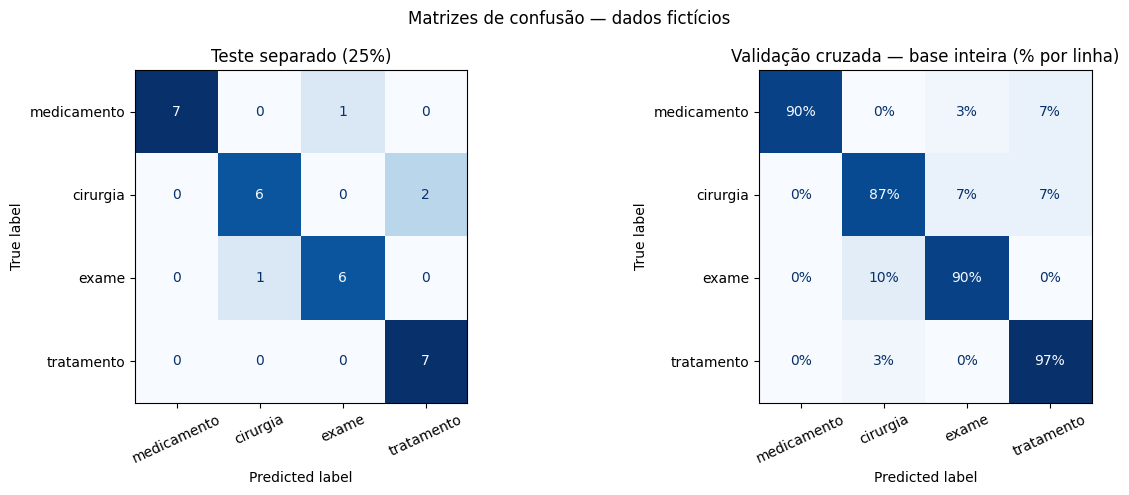

Exemplos que o modelo errou na validação cruzada (bons para estudar):


,texto,categoria,previsto
9,A petição pede um fármaco específico para cont...,medicamento,tratamento
13,O pedido busca garantir o acesso ao princípio ...,medicamento,exame
33,O requerente pede operação para tratamento de ...,cirurgia,tratamento
43,O paciente aguarda ultrassonografia pela rede ...,exame,cirurgia
49,O paciente precisa realizar uma endoscopia dig...,exame,cirurgia
51,O pedido judicial trata da realização de eletr...,exame,cirurgia
69,O paciente aguarda tratamento especializado pa...,tratamento,cirurgia
82,O autor necessita de canabidiol para controle ...,medicamento,tratamento
91,Solicita-se colecistectomia por videolaparosco...,cirurgia,exame
92,A autora necessita de histerectomia indicada p...,cirurgia,exame


In [5]:
predicoes_cv = cross_val_predict(criar_modelo(MultinomialNB(alpha=melhor_alpha)),
                                 df["texto"], df["categoria"],
                                 cv=5)
print(f"Acurácia na validação cruzada (base inteira): {accuracy_score(df['categoria'], predicoes_cv):.1%}")

fig, eixos = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_teste, predicoes, labels=CATEGORIAS, ax=eixos[0],
                                        xticks_rotation=25, cmap="Blues", colorbar=False)
eixos[0].set_title("Teste separado (25%)")
ConfusionMatrixDisplay.from_predictions(df["categoria"], predicoes_cv, labels=CATEGORIAS, ax=eixos[1],
                                        xticks_rotation=25, cmap="Blues", colorbar=False, normalize="true",
                                        values_format=".0%")
eixos[1].set_title("Validação cruzada — base inteira (% por linha)")
plt.suptitle("Matrizes de confusão — dados fictícios")
plt.tight_layout()
plt.show()

erros = df.assign(previsto=predicoes_cv).query("categoria != previsto")
if len(erros):
    print("Exemplos que o modelo errou na validação cruzada (bons para estudar):")
    display(erros)

## 4. Modelo final e explicabilidade
O modelo final é treinado com **todos** os exemplos e a melhor configuração. Em seguida aparecem os termos que mais "puxam" cada categoria: para cada palavra, é a diferença entre o peso dela naquela categoria e o peso médio nas outras.

In [6]:
modelo = criar_modelo(MultinomialNB(alpha=melhor_alpha))
modelo.fit(df["texto"], df["categoria"])

NOMES_TERMOS = modelo.named_steps["vetorizador"].get_feature_names_out()
CLASSES = modelo.named_steps["classificador"].classes_
_pesos = modelo.named_steps["classificador"].feature_log_prob_
# Peso discriminativo: quanto o termo favorece a classe em relação à média das demais.
PESO_DISCRIMINATIVO = np.vstack([
    _pesos[i] - np.delete(_pesos, i, axis=0).mean(axis=0) for i in range(len(CLASSES))
])
EH_PALAVRA = np.char.startswith(NOMES_TERMOS.astype(str), "palavras__")

def termos_mais_fortes(n=10):
    tabela = {}
    for i, classe in enumerate(CLASSES):
        idx = np.where(EH_PALAVRA)[0]
        ordem = idx[np.argsort(PESO_DISCRIMINATIVO[i, idx])[::-1][:n]]
        tabela[classe] = [NOMES_TERMOS[j].split("__", 1)[1] for j in ordem]
    return pd.DataFrame(tabela)[[c for c in CATEGORIAS if c in tabela]]

print(f"Modelo final ({type(modelo.named_steps['classificador']).__name__}) treinado com {len(df)} exemplos.")
print("\nTermos que mais caracterizam cada categoria:")
display(termos_mais_fortes())

Modelo final (MultinomialNB) treinado com 120 exemplos.

Termos que mais caracterizam cada categoria:


,medicamento,cirurgia,exame,tratamento
0,medicamento,cirurgia,exame,tratamento
1,fornecimento,cirurgico,diagnostico,sessoes
2,dispensacao,procedimento,teste,reabilitacao
3,fornecimento medicamento,procedimento cirurgico,investigacao,acompanhamento
4,prescrito,operacao,cintilografia,terapia
5,farmaco,correcao,eletroencefalograma,atendimento
6,uso,cirurgica,cardiologista,especializado
7,receita,catarata,ressonancia,domiciliar
8,remedio,cirurgia correcao,laboratorial,sessoes fisioterapia
9,dispensacao medicamento,intervencao,genetico,fisioterapia


## 5. Extração de texto dos arquivos

In [7]:
from pypdf import PdfReader
from docx import Document

def limpar_texto_extraido(texto):
    texto = re.sub(r"(\w)-\n(\w)", r"\1\2", texto)   # junta palavras hifenizadas na quebra de linha
    texto = re.sub(r"[ \t]+", " ", texto)
    texto = re.sub(r"\n{3,}", "\n\n", texto)
    return texto.strip()


def extrair_texto_pdf(conteudo_bytes):
    leitor = PdfReader(io.BytesIO(conteudo_bytes))
    return "\n".join((pagina.extract_text() or "") for pagina in leitor.pages)


def extrair_texto_docx(conteudo_bytes):
    documento = Document(io.BytesIO(conteudo_bytes))
    partes = [p.text for p in documento.paragraphs if p.text.strip()]
    for tabela in documento.tables:  # também considera conteúdo de tabelas
        for linha in tabela.rows:
            partes.append(" | ".join(celula.text for celula in linha.cells))
    return "\n".join(partes)


def extrair_texto_arquivo(nome_arquivo, conteudo_bytes):
    extensao = nome_arquivo.lower().rsplit(".", 1)[-1] if "." in nome_arquivo else ""
    if extensao == "pdf":
        texto = extrair_texto_pdf(conteudo_bytes)
    elif extensao == "docx":
        texto = extrair_texto_docx(conteudo_bytes)
    elif extensao == "txt":
        try:
            texto = conteudo_bytes.decode("utf-8-sig")
        except UnicodeDecodeError:
            texto = conteudo_bytes.decode("cp1252", errors="replace")
    else:
        raise ValueError("Formato não aceito. Envie um arquivo PDF, DOCX ou TXT.")

    texto = limpar_texto_extraido(texto)
    if not texto:
        raise ValueError("Não foi possível extrair texto deste arquivo. Se for um PDF digitalizado "
                         "como imagem, esta versão ainda não possui OCR.")
    return texto

## 6. Classificação com análise por trechos
Uma petição real tem muito texto que não interessa (qualificação das partes, fundamentação jurídica). Por isso o documento é classificado **inteiro** e também **trecho a trecho**, e o resultado aponta:
- a **categoria principal**, com pontuação e margem sobre a 2ª colocada;
- **pedidos secundários**: outras categorias que aparecem com força em algum trecho;
- os **termos do documento** que mais pesaram na decisão;
- se o caso deve ir para **revisão humana**.

In [8]:
LIMIAR_CONFIANCA = 0.45   # abaixo disso → revisão humana
LIMIAR_MARGEM = 0.15      # 1ª e 2ª categorias muito próximas → revisão humana
LIMIAR_TRECHO = 0.55      # trecho "forte" o bastante para indicar um pedido secundário
TAMANHO_MIN_TRECHO = 40   # caracteres


def dividir_em_trechos(texto):
    blocos = re.split(r"\n\s*\n|(?<=[.;:!?])\s+(?=[A-ZÁÉÍÓÚÂÊÔÃÕÇ])", texto)
    return [b.strip() for b in blocos if len(b.strip()) >= TAMANHO_MIN_TRECHO]


def termos_que_pesaram(texto, classe, n=8):
    vetor = modelo.named_steps["vetorizador"].transform([texto]).toarray()[0]
    i = list(CLASSES).index(classe)
    contrib = vetor * PESO_DISCRIMINATIVO[i] * EH_PALAVRA
    ordem = np.argsort(contrib)[::-1]
    return [NOMES_TERMOS[j].split("__", 1)[1] for j in ordem[:n] if contrib[j] > 0]


def classificar_documento(texto):
    """Retorna um dicionário com o resultado (reutilizado pela exibição e pelo servidor MCP)."""
    if not isinstance(texto, str) or not texto.strip():
        raise ValueError("O documento não contém texto para classificar.")

    probs = modelo.predict_proba([texto])[0]
    ranking = sorted(zip(CLASSES, probs), key=lambda x: x[1], reverse=True)
    (cat1, p1), (_, p2) = ranking[0], ranking[1]
    margem = p1 - p2

    trechos = dividir_em_trechos(texto)
    analise_trechos = []
    if len(trechos) > 1:
        for trecho, pr in zip(trechos, modelo.predict_proba(trechos)):
            k = int(np.argmax(pr))
            analise_trechos.append({"trecho": trecho, "categoria": CLASSES[k], "pontuacao": float(pr[k])})
    secundarias = sorted({t["categoria"] for t in analise_trechos
                          if t["pontuacao"] >= LIMIAR_TRECHO and t["categoria"] != cat1})

    motivos = []
    if p1 < LIMIAR_CONFIANCA:
        motivos.append(f"pontuação baixa ({p1:.0%})")
    if margem < LIMIAR_MARGEM:
        motivos.append(f"categorias próximas (margem de {margem:.0%})")
    if secundarias:
        motivos.append("há possíveis pedidos de outras categorias: " + ", ".join(secundarias))

    return {
        "categoria": cat1,
        "pontuacao": float(p1),
        "margem": float(margem),
        "pontuacoes": {c: float(p) for c, p in ranking},
        "pedidos_secundarios": secundarias,
        "termos_relevantes": termos_que_pesaram(texto, cat1),
        "revisao_humana": bool(motivos),
        "motivos_revisao": motivos,
        "trechos": analise_trechos,
    }


def mostrar_resultado(resultado):
    print(f"Categoria sugerida: {resultado['categoria'].upper()}")
    print(f"Pontuação: {resultado['pontuacao']:.1%}  |  Margem sobre a 2ª: {resultado['margem']:.1%}")
    print("\nPontuações por categoria:")
    for classe, valor in resultado["pontuacoes"].items():
        print(f"  {classe:<12} {'█' * int(valor * 40):<40} {valor:.1%}")
    if resultado["termos_relevantes"]:
        print("\nTermos do documento que mais pesaram:", ", ".join(resultado["termos_relevantes"]))
    if resultado["pedidos_secundarios"]:
        print("Possíveis pedidos secundários:", ", ".join(resultado["pedidos_secundarios"]))
    if resultado["trechos"]:
        fortes = [t for t in resultado["trechos"] if t["pontuacao"] >= LIMIAR_TRECHO]
        print(f"\nTrechos analisados: {len(resultado['trechos'])} (com sinal forte: {len(fortes)})")
        for t in sorted(fortes, key=lambda t: -t["pontuacao"])[:5]:
            print(f"  [{t['categoria']} {t['pontuacao']:.0%}] {t['trecho'][:110]}{'...' if len(t['trecho']) > 110 else ''}")
    if resultado["revisao_humana"]:
        print("\n⚠️  ENCAMINHAR PARA REVISÃO HUMANA:", "; ".join(resultado["motivos_revisao"]))
    else:
        print("\nℹ️  Revise a sugestão antes de utilizá-la. A pontuação não garante que a categoria esteja correta.")

### Teste rápido com textos que não estão na base

In [9]:
exemplos_novos = [
    "Trata-se de ação em que a autora, portadora de esclerose múltipla, requer o fornecimento de natalizumabe, conforme receita.",
    "O menor necessita de sessões semanais de fonoaudiologia e terapia ocupacional.",
    "Requer a realização urgente de ressonância magnética da coluna lombar.",
    "Paciente com indicação de artroplastia de quadril aguarda há dois anos na fila.",
    """EXCELENTÍSSIMO SENHOR JUIZ DE DIREITO.
Maria da Silva, brasileira, CPF 000.000.000-00, vem propor a presente ação.

A autora necessita com urgência de cirurgia de retirada de tumor de mama, conforme laudo do oncologista.

Após a cirurgia, será necessário o fornecimento do medicamento tamoxifeno de uso contínuo, que não está disponível na farmácia.""",
]
for texto in exemplos_novos:
    print("─" * 80)
    print(texto[:160].replace("\n", " ") + ("..." if len(texto) > 160 else ""))
    print()
    mostrar_resultado(classificar_documento(texto))

────────────────────────────────────────────────────────────────────────────────
Trata-se de ação em que a autora, portadora de esclerose múltipla, requer o fornecimento de natalizumabe, conforme receita.

Categoria sugerida: MEDICAMENTO
Pontuação: 94.6%  |  Margem sobre a 2ª: 92.2%

Pontuações por categoria:
  medicamento  █████████████████████████████████████    94.6%
  tratamento                                            2.3%
  cirurgia                                              1.8%
  exame                                                 1.3%

Termos do documento que mais pesaram: fornecimento, receita

ℹ️  Revise a sugestão antes de utilizá-la. A pontuação não garante que a categoria esteja correta.
────────────────────────────────────────────────────────────────────────────────
O menor necessita de sessões semanais de fonoaudiologia e terapia ocupacional.

Categoria sugerida: TRATAMENTO
Pontuação: 99.3%  |  Margem sobre a 2ª: 99.0%

Pontuações por categoria:
  tratamento   ███

## 7. Envio de arquivos (PDF, DOCX ou TXT)
Todos os documentos enviados são processados, e o resumo vira uma tabela exportada em `resultados_natjus.csv`.

In [18]:
from google.colab import files

arquivos_enviados = files.upload()
resumo = []

if not arquivos_enviados:
    print("Nenhum arquivo foi enviado.")
else:
    for nome, conteudo in arquivos_enviados.items():
        print("\n" + "=" * 80)
        print(f"DOCUMENTO: {nome}")
        print("=" * 80)
        try:
            texto_extraido = extrair_texto_arquivo(nome, conteudo)
            print(f"Caracteres extraídos: {len(texto_extraido)}")
            print("\nPrévia do texto extraído:")
            print(texto_extraido[:900] + ("..." if len(texto_extraido) > 900 else ""))
            print("\nRESULTADO DA CLASSIFICAÇÃO")
            resultado = classificar_documento(texto_extraido)
            mostrar_resultado(resultado)
            resumo.append({"arquivo": nome, "categoria": resultado["categoria"],
                           "pontuacao": round(resultado["pontuacao"], 3),
                           "margem": round(resultado["margem"], 3),
                           "pedidos_secundarios": ", ".join(resultado["pedidos_secundarios"]),
                           "revisao_humana": resultado["revisao_humana"],
                           "motivos": "; ".join(resultado["motivos_revisao"])})
        except Exception as erro:
            print(f"Não foi possível processar este arquivo: {erro}")
            resumo.append({"arquivo": nome, "categoria": "ERRO", "motivos": str(erro)})

if resumo:
    tabela_resumo = pd.DataFrame(resumo)
    print("\n\nRESUMO DOS DOCUMENTOS")
    display(tabela_resumo)
    tabela_resumo.to_csv("resultados_natjus.csv", index=False, encoding="utf-8-sig")
    files.download("resultados_natjus.csv")

Saving Solicitacao_NatJus_Marlene_Sakamoto.pdf to Solicitacao_NatJus_Marlene_Sakamoto (1).pdf

DOCUMENTO: Solicitacao_NatJus_Marlene_Sakamoto (1).pdf
Caracteres extraídos: 3682

Prévia do texto extraído:
Centro de Oncologia e Mastologia Santo André
 Avenida das Acácias, 870 – Centro – Santo André/SP – CEP 09010-000 – Tel.: (11) 4433-0000
 SOLICITAÇÃO DE EXAME E RELATÓRIO MÉDICO
PARA ANÁLISE DO NÚCLEO DE APOIO TÉCNICO DO JUDICIÁRIO (NatJus)
1. IDENTIFICAÇÃO DO PACIENTE
Nome
Marlene Sakamoto
Data de nascimento
09/11/1974 (51 anos)
Sexo
Feminino
Endereço
Rua dos Ipês, 132 – Jardim Zaíra – Mauá/SP
Vínculo assistencial
Usuário exclusivo do Sistema Único de Saúde (SUS)
2. IDENTIFICAÇÃO DO MÉDICO SOLICITANTE
Nome
Dr. Zezinho do Pandeiro
Especialidade
Oncologia Clínica / Mastologia
Registro
CRM-SP 000000
Local de atendimento
Centro de Oncologia e Mastologia Santo André – Santo André/SP
3. EXAME SOLICITADO
Procedimento
Teste de assinatura genômica tumoral (painel de expressão de 21 genes –
esco

,arquivo,categoria,pontuacao,margem,pedidos_secundarios,revisao_humana,motivos
0,Solicitacao_NatJus_Marlene_Sakamoto (1).pdf,exame,0.372,0.105,"medicamento, tratamento",True,pontuação baixa (37%); categorias próximas (ma...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Salvar o modelo
O pipeline inteiro (vetorizadores + Naive Bayes) vai para um único arquivo. O servidor MCP da próxima seção usa esse arquivo.

In [19]:
joblib.dump(modelo, "modelo_natjus.joblib")
print("Modelo salvo em modelo_natjus.joblib")
# files.download("modelo_natjus.joblib")  # descomente para baixar e usar o servidor MCP no seu computador

Modelo salvo em modelo_natjus.joblib


## 9. Servidor MCP (Model Context Protocol)

O **MCP** é um protocolo aberto que permite a assistentes de IA (Claude, por exemplo) chamar ferramentas externas.
Aqui o classificador vira um **servidor MCP** com três ferramentas:

| Ferramenta | O que faz |
|---|---|
| `classificar_solicitacao` | recebe o texto da solicitação e devolve categoria, pontuações, pedidos secundários e alerta de revisão |
| `classificar_arquivo` | recebe o caminho de um PDF/DOCX/TXT e faz o mesmo |
| `listar_categorias` | informa as categorias e os termos que mais caracterizam cada uma |

O servidor é gravado no arquivo `servidor_mcp_natjus.py` e testado na célula seguinte por um **cliente MCP** dentro do próprio Colab.

In [20]:
%%writefile servidor_mcp_natjus.py
"""Servidor MCP do classificador NatJus (Naive Bayes).

Uso local:  python servidor_mcp_natjus.py   (precisa de modelo_natjus.joblib na mesma pasta)
"""
import io
import re
from pathlib import Path

import joblib
import numpy as np
from fastmcp import FastMCP

PASTA = Path(__file__).resolve().parent
modelo = joblib.load(PASTA / "modelo_natjus.joblib")
CLASSES = list(modelo.named_steps["classificador"].classes_)
NOMES = modelo.named_steps["vetorizador"].get_feature_names_out().astype(str)
_pesos = modelo.named_steps["classificador"].feature_log_prob_
PESO = np.vstack([_pesos[i] - np.delete(_pesos, i, axis=0).mean(axis=0) for i in range(len(CLASSES))])
EH_PALAVRA = np.char.startswith(NOMES, "palavras__")

LIMIAR_CONFIANCA, LIMIAR_MARGEM, LIMIAR_TRECHO = 0.45, 0.15, 0.55

mcp = FastMCP(
    "NatJus Classificador",
    instructions="Classifica solicitações de saúde (NatJus) em medicamento, cirurgia, exame ou tratamento "
                 "usando Naive Bayes treinado com dados fictícios. O resultado é uma sugestão e exige revisão humana.",
)


def _termos(texto, classe, n=8):
    v = modelo.named_steps["vetorizador"].transform([texto]).toarray()[0]
    contrib = v * PESO[CLASSES.index(classe)] * EH_PALAVRA
    return [NOMES[j].split("__", 1)[1] for j in np.argsort(contrib)[::-1][:n] if contrib[j] > 0]


def _classificar(texto: str) -> dict:
    if not texto or not texto.strip():
        raise ValueError("Texto vazio.")
    probs = modelo.predict_proba([texto])[0]
    ranking = sorted(zip(CLASSES, probs), key=lambda x: x[1], reverse=True)
    cat, p1 = ranking[0]
    margem = p1 - ranking[1][1]

    trechos = [t.strip() for t in re.split(r"\n\s*\n|(?<=[.;:!?])\s+(?=[A-ZÁÉÍÓÚÂÊÔÃÕÇ])", texto)
               if len(t.strip()) >= 40]
    secundarias = set()
    if len(trechos) > 1:
        for pr in modelo.predict_proba(trechos):
            k = int(np.argmax(pr))
            if pr[k] >= LIMIAR_TRECHO and CLASSES[k] != cat:
                secundarias.add(CLASSES[k])

    motivos = []
    if p1 < LIMIAR_CONFIANCA:
        motivos.append(f"pontuação baixa ({p1:.0%})")
    if margem < LIMIAR_MARGEM:
        motivos.append(f"categorias próximas (margem de {margem:.0%})")
    if secundarias:
        motivos.append("possíveis pedidos de outras categorias: " + ", ".join(sorted(secundarias)))

    return {
        "categoria": cat,
        "pontuacao": round(float(p1), 4),
        "margem": round(float(margem), 4),
        "pontuacoes": {c: round(float(p), 4) for c, p in ranking},
        "pedidos_secundarios": sorted(secundarias),
        "termos_relevantes": _termos(texto, cat),
        "revisao_humana": bool(motivos),
        "motivos_revisao": motivos,
        "aviso": "Sugestão automática baseada em dados fictícios; não substitui a análise técnica do NatJus.",
    }


@mcp.tool
def classificar_solicitacao(texto: str) -> dict:
    """Classifica o texto de uma solicitação de saúde em medicamento, cirurgia, exame ou tratamento."""
    return _classificar(texto)


@mcp.tool
def classificar_arquivo(caminho: str) -> dict:
    """Lê um arquivo PDF, DOCX ou TXT do disco e classifica a solicitação contida nele."""
    arquivo = Path(caminho).expanduser()
    ext = arquivo.suffix.lower()
    if ext == ".pdf":
        from pypdf import PdfReader
        texto = "\n".join((p.extract_text() or "") for p in PdfReader(str(arquivo)).pages)
    elif ext == ".docx":
        from docx import Document
        texto = "\n".join(p.text for p in Document(str(arquivo)).paragraphs)
    elif ext == ".txt":
        dados = arquivo.read_bytes()
        try:
            texto = dados.decode("utf-8-sig")
        except UnicodeDecodeError:
            texto = dados.decode("cp1252", errors="replace")
    else:
        raise ValueError("Formato não aceito. Use PDF, DOCX ou TXT.")
    if not texto.strip():
        raise ValueError("Nenhum texto extraído (PDF digitalizado como imagem não é suportado).")
    return {"arquivo": arquivo.name, **_classificar(texto)}


@mcp.tool
def listar_categorias(termos_por_categoria: int = 8) -> dict:
    """Lista as categorias do modelo e os termos que mais caracterizam cada uma."""
    idx = np.where(EH_PALAVRA)[0]
    return {c: [NOMES[j].split("__", 1)[1] for j in idx[np.argsort(PESO[i, idx])[::-1][:termos_por_categoria]]]
            for i, c in enumerate(CLASSES)}


if __name__ == "__main__":
    mcp.run()

Overwriting servidor_mcp_natjus.py


In [13]:
import importlib, sys, json
from fastmcp import Client

sys.path.insert(0, ".")
import servidor_mcp_natjus
importlib.reload(servidor_mcp_natjus)

with open("solicitacao_teste.txt", "w", encoding="utf-8") as f:
    f.write("A parte autora requer a realização de colonoscopia e biópsia para investigação diagnóstica.")

async with Client(servidor_mcp_natjus.mcp) as cliente:
    ferramentas = await cliente.list_tools()
    print("Ferramentas expostas pelo servidor MCP:")
    for ferramenta in ferramentas:
        print(f"  • {ferramenta.name}: {ferramenta.description}")

    print("\n→ classificar_solicitacao")
    r = await cliente.call_tool("classificar_solicitacao",
                                {"texto": "Solicito o fornecimento de adalimumabe para tratamento de doença de Crohn."})
    print(json.dumps(r.data, ensure_ascii=False, indent=2))

    print("\n→ classificar_arquivo")
    r = await cliente.call_tool("classificar_arquivo", {"caminho": "solicitacao_teste.txt"})
    print(json.dumps(r.data, ensure_ascii=False, indent=2))

    print("\n→ listar_categorias")
    r = await cliente.call_tool("listar_categorias", {"termos_por_categoria": 5})
    print(json.dumps(r.data, ensure_ascii=False, indent=2))

Ferramentas expostas pelo servidor MCP:
  • classificar_solicitacao: Classifica o texto de uma solicitação de saúde em medicamento, cirurgia, exame ou tratamento.
  • classificar_arquivo: Lê um arquivo PDF, DOCX ou TXT do disco e classifica a solicitação contida nele.
  • listar_categorias: Lista as categorias do modelo e os termos que mais caracterizam cada uma.

→ classificar_solicitacao
{
  "categoria": "medicamento",
  "pontuacao": 0.9246,
  "margem": 0.8648,
  "pontuacoes": {
    "medicamento": 0.9246,
    "tratamento": 0.0598,
    "cirurgia": 0.0088,
    "exame": 0.0068
  },
  "pedidos_secundarios": [],
  "termos_relevantes": [
    "fornecimento",
    "doenca",
    "tratamento doenca"
  ],
  "revisao_humana": false,
  "motivos_revisao": [],
  "aviso": "Sugestão automática baseada em dados fictícios; não substitui a análise técnica do NatJus."
}

→ classificar_arquivo
{
  "arquivo": "solicitacao_teste.txt",
  "categoria": "exame",
  "pontuacao": 0.9858,
  "margem": 0.9766,
  "pont

### Usando o servidor MCP fora do Colab (opcional)
1. Baixe `modelo_natjus.joblib` e `servidor_mcp_natjus.py` para a mesma pasta.
2. Instale as dependências: `pip install scikit-learn pypdf python-docx joblib fastmcp`
3. No Claude Desktop, adicione ao arquivo `claude_desktop_config.json`:

```json
{
  "mcpServers": {
    "natjus": {
      "command": "python",
      "args": ["C:/caminho/para/servidor_mcp_natjus.py"]
    }
  }
}
```
4. Reinicie o Claude Desktop e peça, por exemplo: *"Classifique a solicitação do arquivo C:/docs/peticao.pdf"*.

> Use a **mesma versão do scikit-learn** do Colab ao carregar o `.joblib` (confira com `import sklearn; sklearn.__version__`).

## Limitações
- Base **pequena e fictícia**: os números de acurácia mostram que o método funciona, mas não dizem como ele se sairia com petições reais.
- Naive Bayes supõe independência entre as palavras, e as "pontuações" não são probabilidades calibradas.
- PDFs digitalizados (imagem) precisam de OCR, que não está incluído.
- Uma solicitação pode ter mais de um pedido. A análise por trechos sinaliza isso, mas a decisão final é humana.